# HNSW retrieval loss analysis (Notebook 07 dataset)

Read-only follow-up to Notebook 07: original 100 queries, 1M indexed molecules, original measured-pass-0 responses at each k. Generated Markdown, CSV and PNG/SVG files go to a new directory under `experiments/results/hnsw_retrieval_loss/`; Notebook 07 and its artifacts are hash-checked for preservation. Heavy logic follows the repository convention of living in a Python module.

In [1]:
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
EXPERIMENT = ROOT / "experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333"
PRIMARY_K = 10
DISPLAY_CUTOFF = 0.50  # inclusive exact float64 Tanimoto cutoff

print("Experiment:", EXPERIMENT)
print("Primary analysis: 1M indexed molecules, 100 original queries, k=", PRIMARY_K,
      ", T >=", DISPLAY_CUTOFF)

Experiment: /home/ruben/Coding Projects/chemtellect/experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333
Primary analysis: 1M indexed molecules, 100 original queries, k= 10 , T >= 0.5


## Verify the historical evidence

The original loader verifies the run inventory and SHA-256 hashes, raw acquisition, fingerprint artifact, query/index mappings, exact top-k, all measured response diagnostics, and original quality evaluations. The original evaluation source files must match their recorded hashes. No search engine is run. The full persisted float64 score matrix is reused; reconstruction is unnecessary for this experiment.

In [3]:
from IPython.display import display, Markdown, Image
from chemtellect import hnsw_loss_analysis as loss

original = loss.load_original(ROOT, EXPERIMENT)
print("Verified original run:", original["run"])
print("Authoritative score matrix:", original["scores"].shape, original["scores"].dtype)
print("Own historical responses at k:", original["report"]["settings"]["candidate_counts"])
print("Historical quality pass:", original["report"]["settings"]["designated_measured_pass_index"])

Verified original run: /home/ruben/Coding Projects/chemtellect/experiments/results/hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000000/run_ea2725c6bba24a8986eb54e24d1c76ba
Authoritative score matrix: (100, 1000000) float64
Own historical responses at k: [10, 25, 50, 100]
Historical quality pass: 0


## Reproduce recall and measure display loss

Each query/k has mandatory strict winners and a boundary tie group. Missing boundary slots retain an ambiguous identity over all unreturned compounds at the tied score. At each cutoff, count full-catalog matches G, exact slots E=min(k,G), unique qualifying HNSW slots H, count loss E−H, qualifying tie-aware membership loss, strongest qualifying miss, and matches beyond the cap G−E. Recall is undefined when G=0. Assertions cross-check all 1,600 query/k/cutoff rows against saved evaluations and the primary Notebook 07 summaries.

In [4]:
analysis = loss.analyze(original, PRIMARY_K, DISPLAY_CUTOFF)
ten = analysis["recalls"].query("k == 10")
print(f"Mean recall@10: {100*ten.tie_aware_recall.mean():.1f}%")
print(f"Minimum recall@10: {100*ten.tie_aware_recall.min():.0f}%")
print("Every query tied at minimum (zero-based):", analysis["worst"])
primary = analysis["primary"]
print("Qualifying queries:", int((primary.G > 0).sum()))
print(f"HNSW mean catalog-threshold recall: {100*primary.hnsw_threshold_recall.mean():.2f}%")
print(f"Exact mean catalog-threshold recall: {100*primary.exact_threshold_recall.mean():.2f}%")
display(primary.outcome.value_counts().reindex(loss.OUTCOMES, fill_value=0).rename("Queries out of 100").to_frame())
display(primary.query("qualifying_top_k_neighbors_missed > 0")[["query_position", "query_source_id", "G", "E", "H", "qualifying_slots_lost", "qualifying_top_k_neighbors_missed", "highest_scoring_qualifying_miss"]])

Mean recall@10: 97.4%
Minimum recall@10: 20%
Every query tied at minimum (zero-based): [53]
Qualifying queries: 87
HNSW mean catalog-threshold recall: 83.07%
Exact mean catalog-threshold recall: 86.81%


,Queries out of 100
outcome,
no qualifying catalog match,13
full tie-aware recovery of qualifying top-k,83
same displayed count but weaker membership,0
fewer qualifying results displayed,4


,query_position,query_source_id,G,E,H,qualifying_slots_lost,qualifying_top_k_neighbors_missed,highest_scoring_qualifying_miss
29,7,objectid:5bc9ffe5f12700529cf7967e,1,1,0,1,1,0.565217
49,12,objectid:5be5c005f127006b84d7beca,2,2,1,1,1,0.506667
145,36,objectid:5bee5f47f127007b1b99663d,2,2,0,2,2,0.581818
201,50,objectid:5bf0db22f127006fad61fea4,4,4,1,3,3,0.568182


## Export the standalone report and supporting evidence

Export creates a fresh analysis directory, preserving the original experiment. The report answers the four worst-query questions, includes rank/ID tables and the full boundary tie group, explains denominators before every table, and links all CSVs and three figures (PNG plus SVG). The manifest records successful checks and generated-file hashes; provenance records historical paths, run ID, source-code hashes and preserved artifact hashes.

In [5]:
REPORT = loss.export(original, analysis, PRIMARY_K, DISPLAY_CUTOFF)
print("Standalone report:", REPORT)
print("All supporting figures, CSV tables, provenance and manifest:", REPORT.parent)
display(Markdown("\n".join(line for line in REPORT.read_text().splitlines() if not line.startswith("!["))))

Standalone report: /home/ruben/Coding Projects/chemtellect/experiments/results/hnsw_retrieval_loss/chemicalspace_new/scale_1m_00/experiment_20261112_0333/analysis_7689244e2b5a44bf8ae66921f961ed93/hnsw_retrieval_loss_report.md
All supporting figures, CSV tables, provenance and manifest: /home/ruben/Coding Projects/chemtellect/experiments/results/hnsw_retrieval_loss/chemicalspace_new/scale_1m_00/experiment_20261112_0333/analysis_7689244e2b5a44bf8ae66921f961ed93


# HNSW retrieval loss at the 1M proof-of-concept scale

The 20% recall@10 query (row 53) lost eight genuine top-ten slots, but its strongest miss was only **0.4791666667**: at the proposed **T ≥ 0.50** product cutoff, both engines would have displayed **zero compounds**, so neither displayed count nor displayed quality changed. Across the original 100 searches at k=10, **4 searches changed**: four displayed fewer qualifying compounds, losing seven slots in total; none returned the same count with weaker qualifying membership. The strongest consequential miss was **0.5818181818**, in query row 36, whose exact two qualifying compounds both disappeared from the HNSW display.

## Evidence, scope, and definitions

Dataset: `chemicalspace_new/scale_1m_00`. Experiment: [`experiment_20261112_0333`](../../../../../pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333/state.json). Primary source: [`run_ea2725c6bba24a8986eb54e24d1c76ba`](../../../../../hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000000/run_ea2725c6bba24a8986eb54e24d1c76ba/manifest.json), index size 1,000,000; 100 original held-out queries, primary k=10, inclusive display cutoff 0.50. Each k=10, 25, 50, 100 uses its own `benchmark.designated.hnsw.<k>[query_position]` response from measured pass 0, checked against the corresponding `measured_results` request. No HNSW graph was built, loaded, or searched for this analysis.

The original [`exact_scores.npy`](../../../../../hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000000/run_ea2725c6bba24a8986eb54e24d1c76ba/exact_scores.npy) supplies all 100 × 1M RDKit float64 similarities. The original [`ground_truth_top_k.json`](../../../../../hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000000/run_ea2725c6bba24a8986eb54e24d1c76ba/ground_truth_top_k.json), [`records.json`](../../../../../hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000000/run_ea2725c6bba24a8986eb54e24d1c76ba/records.json), [`parent_split.json`](../../../../../pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333/parent_split.json), and [`fingerprint manifest`](../../../../../../../data/processed/chemicalspace_new/scale_1m_00/fingerprints/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/manifest.json) were verified using the project loader, including hashes, packed fingerprints, ordered identities, raw acquisition linkage, and saved response diagnostics. All required artifacts were present; no historical question remains unresolved because of missing data. The source files defining historical evaluation match their recorded SHA-256 hashes.

The current `hnsw_reporting.py` presentation writer differs from its run-time hash. It is not used here to compute scores or metrics. Both historical and current hashes are recorded in provenance; all six recorded numerical benchmark/adapter sources match. The original loader successfully recomputes and verifies the saved quality evaluations.

All rankings, equality ties, and cutoff decisions use full precision. Displayed decimals are presentation only; CSV floats round-trip to the original binary float64 values. Exact ranking breaks equal scores by original index position; recovery credits every strict winner and at most the available slots at the exact k-th score. An equally scoring replacement at that boundary is valid. A deficit at a tied boundary is a count of missing slots in the entire tied group, not an assertion that one arbitrarily selected tied compound had to be returned.

One per-query CSV row is one original query × its own k-response × cutoff (1,600 rows). `G` counts all qualifying catalog compounds; `E=min(k,G)` counts exact qualifying slots; `H` counts unique returned compounds qualifying by exact score. `E−H` measures display-count loss. `qualifying_top_k_neighbors_missed` measures tie-aware membership loss and can exceed count loss. `matches_beyond_output_cap=G−E` is cap loss even for exact retrieval. Threshold recall is H/G (exact: E/G), undefined for G=0. See [per-query metrics](per_query_metrics.csv) and [all top-k recalls](top_k_recall.csv). Query/index rows are zero-based; raw line numbers and response ranks are one-based. Compound identity means source ID, preserving distinct records even when their fingerprints have equal similarity.

## Reproducing Notebook 07

The unit below is a summary across the 100 original k=10 searches. Threshold-recall means average only the 87 queries with G>0 at 0.50; they do not divide recovered slots by ten. Reported percentages are rounded only after averaging.

| Measure | Denominator | Recomputed | Notebook 07 |
| --- | --- | --- | --- |
| Mean tie-aware recall@10 | 100 queries | 97.4% | 97.4% |
| Minimum tie-aware recall@10 | 100 queries | 20% | 20% |
| Qualifying queries at 0.50 | 100 queries | 87 | 87 |
| Mean HNSW threshold recall at 0.50 | 87 qualifying queries | 83.07% | 83.07% |
| Mean exact threshold recall at 0.50 | 87 qualifying queries | 86.81% | 86.81% |

All summaries reproduce to their displayed precision, with no discrepancy. The original saved per-query threshold evaluations and top-k recall diagnostics also match the recomputed values. The exact threshold mean below 100% reflects the output cap; the additional HNSW shortfall reflects retrieval loss. [Cross-check CSV](notebook07_crosscheck.csv).

## The minimum-recall query

Every minimum-recall query is included: **row 53** (query number 54), raw line **408132**, source compound **`objectid:5bf159eff127006fadac2157`**. Canonical SMILES: `Cc1nnc(Cn2c(O)c[nH]c2=O)n1C`. Independent slot accounting gives 2/10 = 20% recovery.

Each row in the following table compares the same response rank in the two original ten-result lists. Compound IDs resolve score overlaps; a same-rank entry is not a claim of a chemical analogue pairing. HNSW scores here are exact RDKit scores for its returned IDs, not 1 minus its rounded native distances. The boundary group is shared across ranks and must not be counted as a separate miss per listed ID.

| Rank | Exact compound | Exact T | Exact recovery | HNSW compound | HNSW exact T | HNSW status |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | objectid:5bf0f75bf127006fad706c2c | 0.4791666667 | genuine strict miss | objectid:5bf07163f127006c7a19a007 | 0.4489795918 | recovered strict winner |
| 2 | objectid:5bf15f5cf127006fadaf2d5e | 0.4666666667 | genuine strict miss | objectid:5bf0eb05f127006fad6c05b9 | 0.4375 | valid boundary-score recovery |
| 3 | objectid:5bf0b078f127006c7a38c6cf | 0.4583333333 | genuine strict miss | objectid:5bf0f463f127006fad6f21f0 | 0.4347826087 | weaker replacement below top-k boundary |
| 4 | objectid:5bf17941f127006fadc1439a | 0.4565217391 | genuine strict miss | objectid:5bee24ecf127007b1b7b9c36 | 0.42 | weaker replacement below top-k boundary |
| 5 | objectid:5bf07163f127006c7a19a007 | 0.4489795918 | recovered identity | objectid:5bdf158bf1270079ac2f5c52 | 0.4081632653 | weaker replacement below top-k boundary |
| 6 | objectid:5bf179e5f127006fadc1b355 | 0.4444444444 | genuine strict miss | objectid:5bdcad39f1270023c1844543 | 0.4 | weaker replacement below top-k boundary |
| 7 | objectid:5bf17372f127006fadbd0799 | 0.4444444444 | genuine strict miss | objectid:5bf06f03f127006c7a1910c9 | 0.3962264151 | weaker replacement below top-k boundary |
| 8 | objectid:5bde8415f1270079acef8be5 | 0.44 | genuine strict miss | objectid:5bf13010f127006fad930e7f | 0.3921568627 | weaker replacement below top-k boundary |
| 9 | objectid:5bf0eb05f127006fad6c05b9 | 0.4375 | recovered identity | objectid:5be129e9f12700469ab78769 | 0.3913043478 | weaker replacement below top-k boundary |
| 10 | objectid:5bf0f6aef127006fad702e4a | 0.4375 | boundary group: 1 missing slots; identity ambiguous | objectid:5bf1595bf127006fadabdce1 | 0.387755102 | weaker replacement below top-k boundary |

[Full neighbor details and canonical SMILES](worst_query_neighbor_detail.csv).

**1. Strongest genuine miss:** T=0.4791666666666667, compound `objectid:5bf0f75bf127006fad706c2c`.

**2. Miss severity intervals:** T<0.30: **0**; 0.30≤T<0.50: **8**; 0.50≤T<0.70: **0**; T≥0.70: **0**. The eight individual missing-slot scores, in descending order, are: 0.4791666666666667, 0.4666666666666667, 0.4583333333333333, 0.45652173913043476, 0.4444444444444444, 0.4444444444444444, 0.44, 0.4375.

At the top-ten boundary T=0.4375, 4 catalog compounds tie for 2 exact slots. HNSW recovered 1 slot, leaving **1 missing slot**. The full tied group is `objectid:5bf0eb05f127006fad6c05b9`, `objectid:5bf0f6aef127006fad702e4a`, `objectid:5bf15c70f127006fadad525d`, `objectid:5bf159e7f127006fadac1e7e`. Only one of the unreturned group members is needed to fill the remaining slot; its identity is ambiguous. [Tie-aware miss groups](genuine_miss_groups.csv).

**3. Display at 0.50:** exact **0**, HNSW **0** (G=0). There were no stronger qualifying neighbors to miss and no displayed replacements. Below the cutoff, HNSW kept two valid exact slots and filled the other eight with weaker scores ranging from 0.4347826087 to 0.3877551020; the ID table identifies them.

**4. Display impact:** **neither** count nor quality changed at the proposed 0.50 cutoff. Before filtering, both ten-result membership and score quality were worse. Threshold recall remains undefined for this query, rather than being scored as 0% or 100%.


[Vector figure](worst_query_scores.svg). Full precision and compound identities are in the neighbor CSV.

## Practical loss across all 100 searches

The following table has one row per outcome at k=10 and T≥0.50. Counts use all 100 queries. Percentages use only the 87 queries with a qualifying catalog match; no-match percentage is therefore inapplicable. The categories are exclusive, assigned in this order: no match; fewer displayed; same count with missing qualifying top-k membership; otherwise full qualifying recovery. Full recovery does not imply that G fits within ten slots.

| Outcome | Count | % of 87 qualifying queries |
| --- | --- | --- |
| no qualifying catalog match | 13 | inapplicable |
| full tie-aware recovery of qualifying top-k | 83 | 95.40% |
| same displayed count but weaker membership | 0 | 0.00% |
| fewer qualifying results displayed | 4 | 4.60% |

[Outcome CSV](primary_outcomes.csv).

The qualifying searches had **2,260** catalog matches, **513** exact qualifying slots and **506** HNSW qualifying slots. **1,747** matches were beyond the exact ten-result cap. These are sums of query–compound matches; a catalog compound may qualify for more than one query.

Each row below is one of the four affected searches (denominator: 100 total, 87 qualifying). `Missed` is qualifying top-ten membership loss, retained here even for queries that also lose displayed slots. E and H are displayed counts after filtering; G is the full qualifying catalog count.

| query_position | G | E | H | qualifying_slots_lost | qualifying_top_k_neighbors_missed | highest_scoring_qualifying_miss | matches_beyond_output_cap |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 7 | 1 | 1 | 0 | 1 | 1 | 0.5652173913 | 0 |
| 12 | 2 | 2 | 1 | 1 | 1 | 0.5066666667 | 0 |
| 36 | 2 | 2 | 0 | 2 | 2 | 0.5818181818 | 0 |
| 50 | 4 | 4 | 1 | 3 | 3 | 0.5681818182 | 0 |

[Affected-search metrics](affected_queries.csv).

Each row in the next table is a genuinely missed qualifying compound for those four searches (seven query–compound pairs). The HNSW entry at the same original rank shows the rank displacement; it is not a chemical pairing or a claim that HNSW explicitly chose one structure instead of another. In query 50 the retained 0.50 compound moves up to rank 1; it must not be mistaken for a newly substituted compound. The other six same-rank entries shown here fail the 0.50 cutoff.

| Query | Rank | Missed compound | Missed T | HNSW same-rank compound | HNSW same-rank T |
| --- | --- | --- | --- | --- | --- |
| 7 | 1 | objectid:5be4ecfaf127006b8485fb28 | 0.5652173913 | objectid:5bc9c503f12700529ce20ce1 | 0.4893617021 |
| 12 | 2 | objectid:5be83deef127003b0c82e930 | 0.5066666667 | objectid:5bda7700f127007f4760d292 | 0.4054054054 |
| 36 | 1 | objectid:5bde68d2f1270079acdfe36d | 0.5818181818 | objectid:5befd9e0f127006c7acb9237 | 0.4909090909 |
| 36 | 2 | objectid:5beebcc0f127007b1bc9d202 | 0.5263157895 | objectid:5bdec660f1270079ac0d4546 | 0.46875 |
| 50 | 1 | objectid:5bf05096f127006c7a077a03 | 0.5681818182 | objectid:5bee0702f127007b1b6db779 | 0.5 |
| 50 | 2 | objectid:5bdf03c7f1270079ac269d42 | 0.52 | objectid:5bf04147f127006c7afd146b | 0.4901960784 |
| 50 | 4 | objectid:5befd342f127006c7ac772f3 | 0.5 | objectid:5bf12b48f127006fad90257e | 0.4782608696 |

[Displacement CSV](qualifying_miss_displacements.csv); [complete affected response lists](affected_neighbor_detail.csv). Query rows 7 and 36 lost all qualifying results (1→0 and 2→0); rows 12 and 50 retained a qualifying compound but lost 1 and 3 slots respectively (2→1 and 4→1).

## Changing the cutoff

Each row below and each stacked bar represent the same 100 k=10 responses, with a different inclusive cutoff. The four outcome columns count queries, not compounds; “qualifying queries” is the denominator for the recovery percentages. The [full summary CSV](cutoff_k_summary.csv) includes those explicitly labeled percentages, slot totals, membership losses, cap losses, and both catalog-threshold recall means.

| Cutoff | Qualifying queries | No catalog match | Full qualifying recovery | Same count, weaker | Fewer displayed |
| --- | --- | --- | --- | --- | --- |
| 0.3 | 100 | 0 | 89 | 11 | 0 |
| 0.5 | 87 | 13 | 83 | 0 | 4 |
| 0.7 | 10 | 90 | 10 | 0 | 0 |
| 0.9 | 0 | 100 | 0 | 0 | 0 |

At 0.30, all 100 queries have results: 89% have full qualifying recovery and 11% return the same count with weaker membership. Both engines have the same 5.7636% mean catalog-threshold recall at 0.30, yet HNSW missed 26 qualifying top-ten slots across those 11 queries, replacing them with weaker compounds that still qualify. Threshold recall alone hides this membership loss. At 0.50, 83/87 (95.40%) qualifying queries have full recovery and 4/87 (4.60%) display fewer. At 0.70, 10/10 qualifying queries have full recovery, but 90/100 searches have no qualifying catalog match. At 0.90, all 100 have no match and threshold recall is undefined. Higher cutoffs remove the missed-score range and many searchable query results; this is not evidence of improved HNSW traversal or a reason by itself to raise a product cutoff.


[Vector figure](display_outcomes.svg). The gray no-match segments stay visible.

## Severity across the original k=10 searches

The figure uses one point per query with at least one genuine top-ten miss, taking its highest missing score after tie credit. **89/100** queries had no genuine miss; **11/100** did. The minimum-recall query (row 53, red) was **not** the query with the strongest miss: row 36 missed T=0.5818181818. No genuine top-ten miss reached 0.70. [Per-query severities and recall](top_k_recall.csv); [individual misses and ambiguous boundary groups](genuine_miss_groups.csv).


[Vector figure](miss_severity.svg). Reference lines are 0.30, 0.50, and 0.70.

## Secondary comparisons across k

Each row below is the original pass-0 search set at that k, always 100 queries and 87 qualifying queries at T≥0.50. Count losses and same-count membership losses are mutually exclusive query counts. Highest miss is the maximum exact score among genuinely missed qualifying slots, not the average. The run is shared; each request is identified separately by k, query row, pass index, and response key in the CSVs.

| k | Queries losing displayed slots | Same count, weaker membership | Highest qualifying miss |
| --- | --- | --- | --- |
| 10 | 4 | 0 | 0.5818181818 |
| 25 | 4 | 0 | 0.5818181818 |
| 50 | 4 | 0 | 0.5818181818 |
| 100 | 4 | 0 | 0.5818181818 |

[Secondary comparison CSV](secondary_k_comparison.csv). The affected rows remain 7, 12, 36, and 50 and the seven qualifying misses persist in each k’s own response. Increasing the output cap alone did not repair those misses. Exact mean catalog-threshold recall improves from 86.81% at k=10 to 93.31%, 95.25%, and 96.25% at k=25, 50, and 100; HNSW reaches 83.07%, 89.57%, 91.51%, and 92.51%. At 0.30, larger k exposes more membership loss: same-count/weaker queries are 11, 20, 37, and 66 and fewer-displayed queries are 0, 1, 2, and 4 respectively. At 0.70 and 0.90 the outcomes are unchanged across k. All 16 k/cutoff combinations are in [the complete summary](cutoff_k_summary.csv).

## Provenance and verification

Source run ID: `ea2725c6bba24a8986eb54e24d1c76ba`. Fingerprint artifact ID: `56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0`. Split ID: `17cc63bd0df36cbc162e424afaaf6b44a7384df3b20cd2eac2f36477d3ee004b`. [Machine-readable source paths and SHA-256 evidence](provenance.json); [generated-file manifest and verification](manifest.json). The checks assert that each outcome partition sums to 100 for all 16 combinations; 0≤H≤E≤k for all 1,600 rows; E equals qualifying records in the exact top-k; all per-query metrics reproduce saved evaluations; the primary summaries round to Notebook 07’s values; every local Markdown link and figure resolves; and the original Notebook 07, original experiment files, primary run, and fingerprint files retain their initial hashes. Generated results live in a separate analysis directory.

## Implications for the next HNSW tuning experiment

Treat 0.50 as a proposed product display cutoff and 1M as the proof-of-concept scale. The alarming 20% query is irrelevant to that display, while four searches have a measurable scientist-facing loss, including two becoming empty and a missed compound at 0.5818. For a new experiment, keep these fixed queries, exact scores, and tie policy, and explicitly track lost qualifying slots, same-count membership degradation, strongest miss, and empty displays alongside recall and latency. Start by varying `efSearch` above the original 200 on the saved graph, then, if needed, compare fresh graphs with changed M/efConstruction against the original M=16/efConstruction=200. Use new run IDs and record each query/k response. Increasing k alone left these qualifying misses unresolved. Validate across additional held-out queries and graph builds before choosing a product setting; these fixed-query similarity measurements do not establish biological utility or performance at 100M molecules.

## Figures

Score lines retain original response rank; their compound identities and tie interpretation are in `worst_query_neighbor_detail.csv`. All four outcome bars count the same 100 queries. The severity figure uses one point per query with a genuine miss, so its denominator differs from the outcome bars.

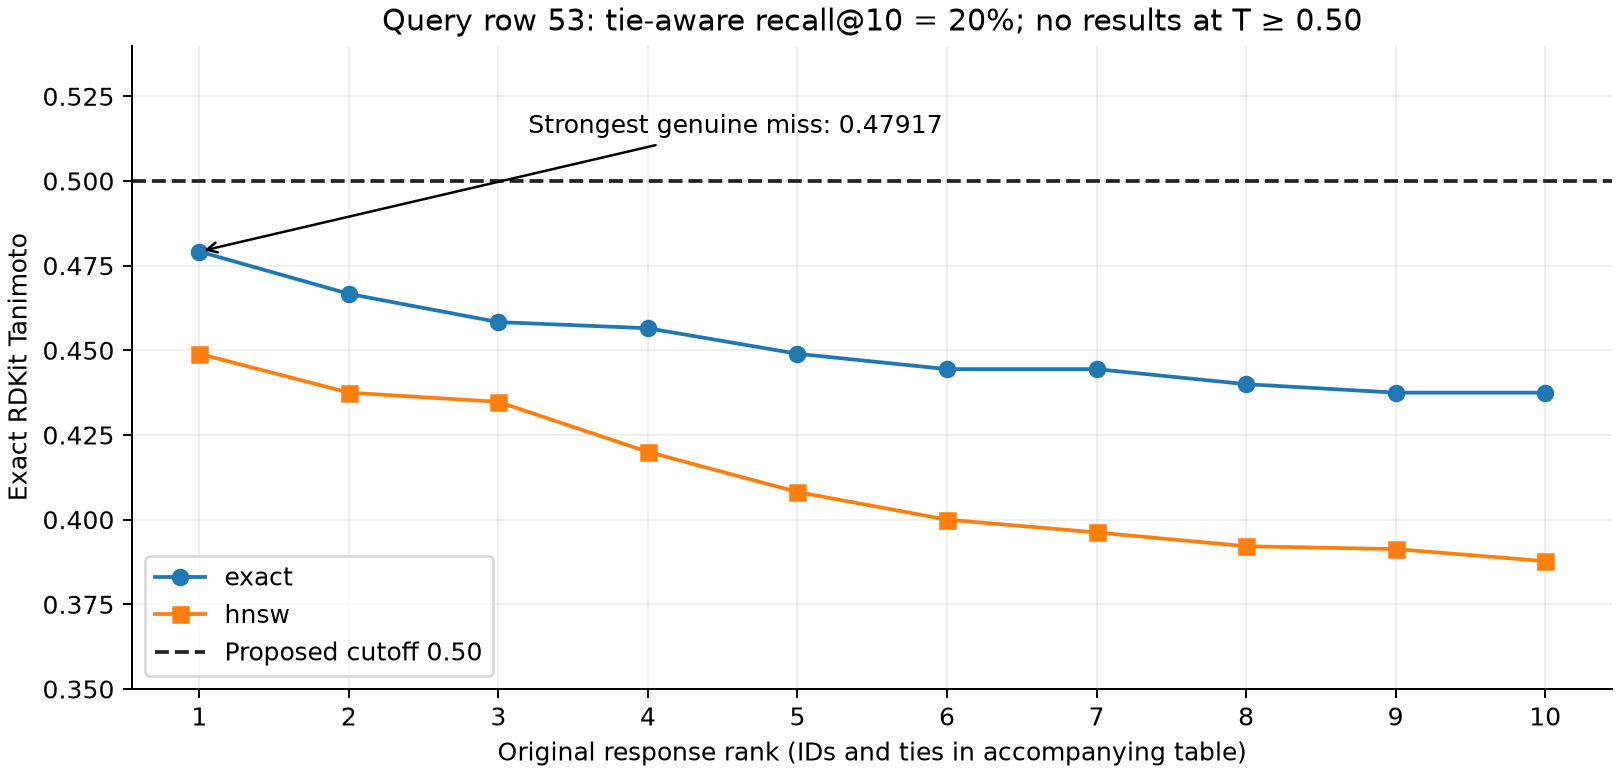

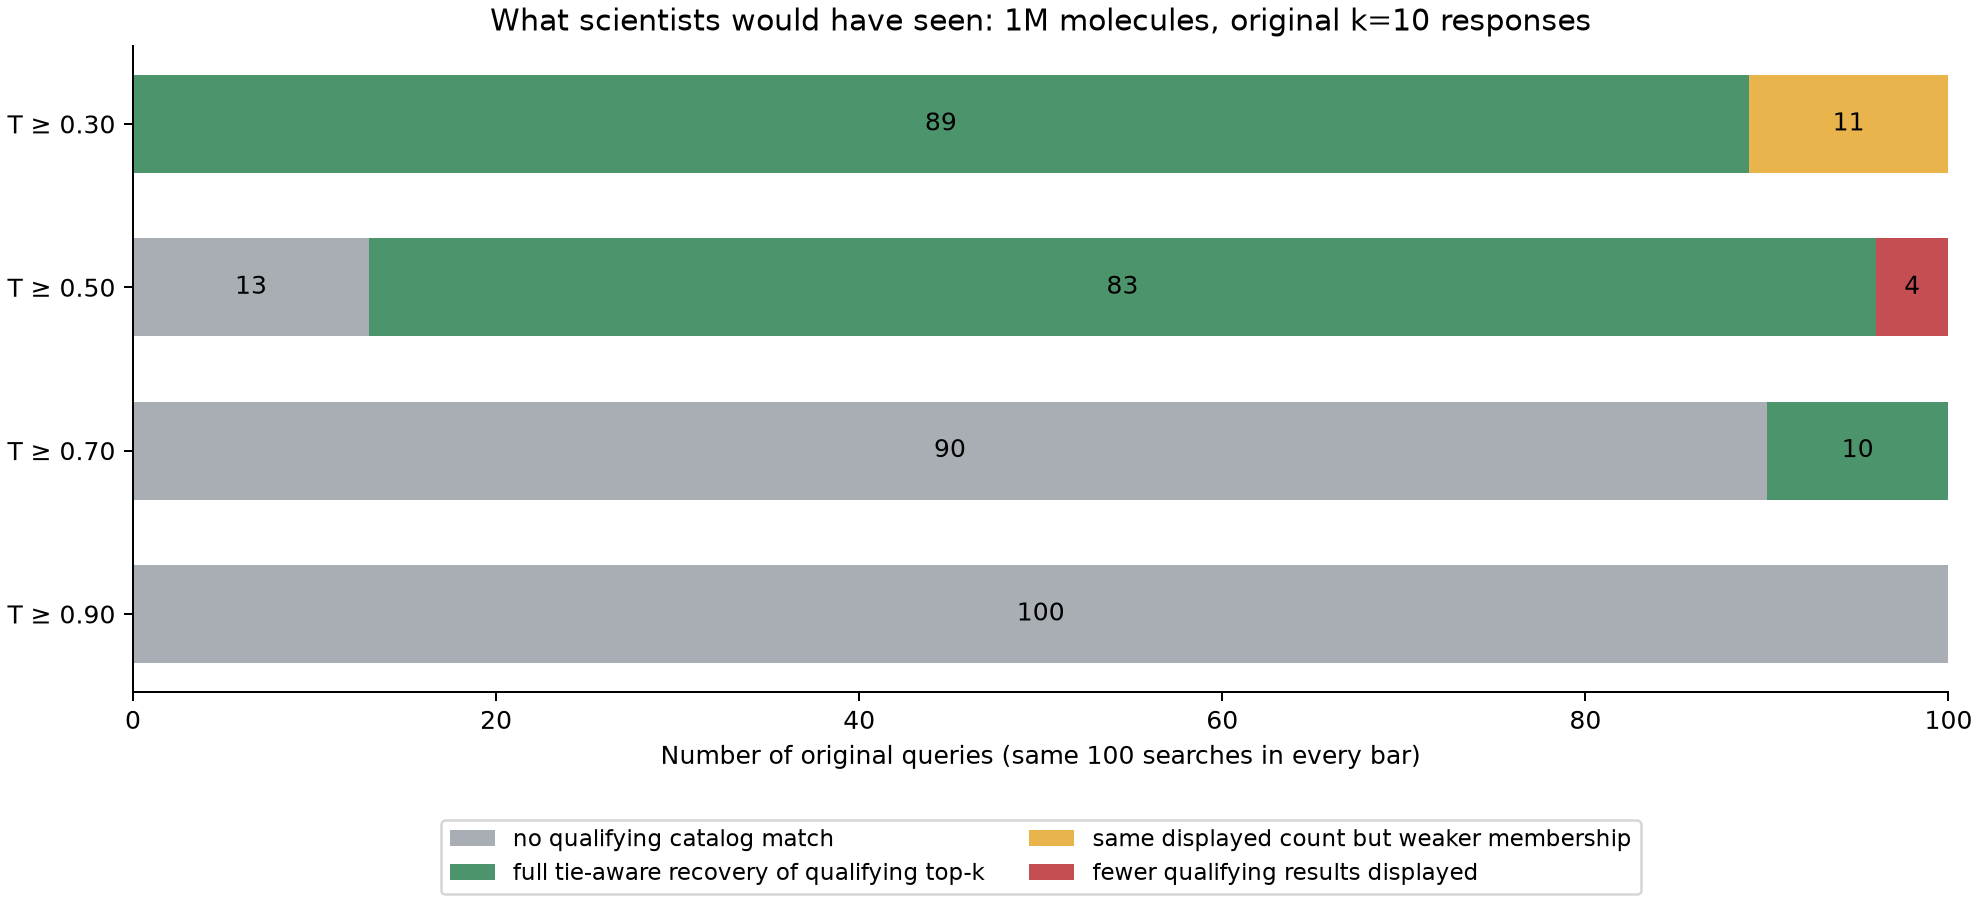

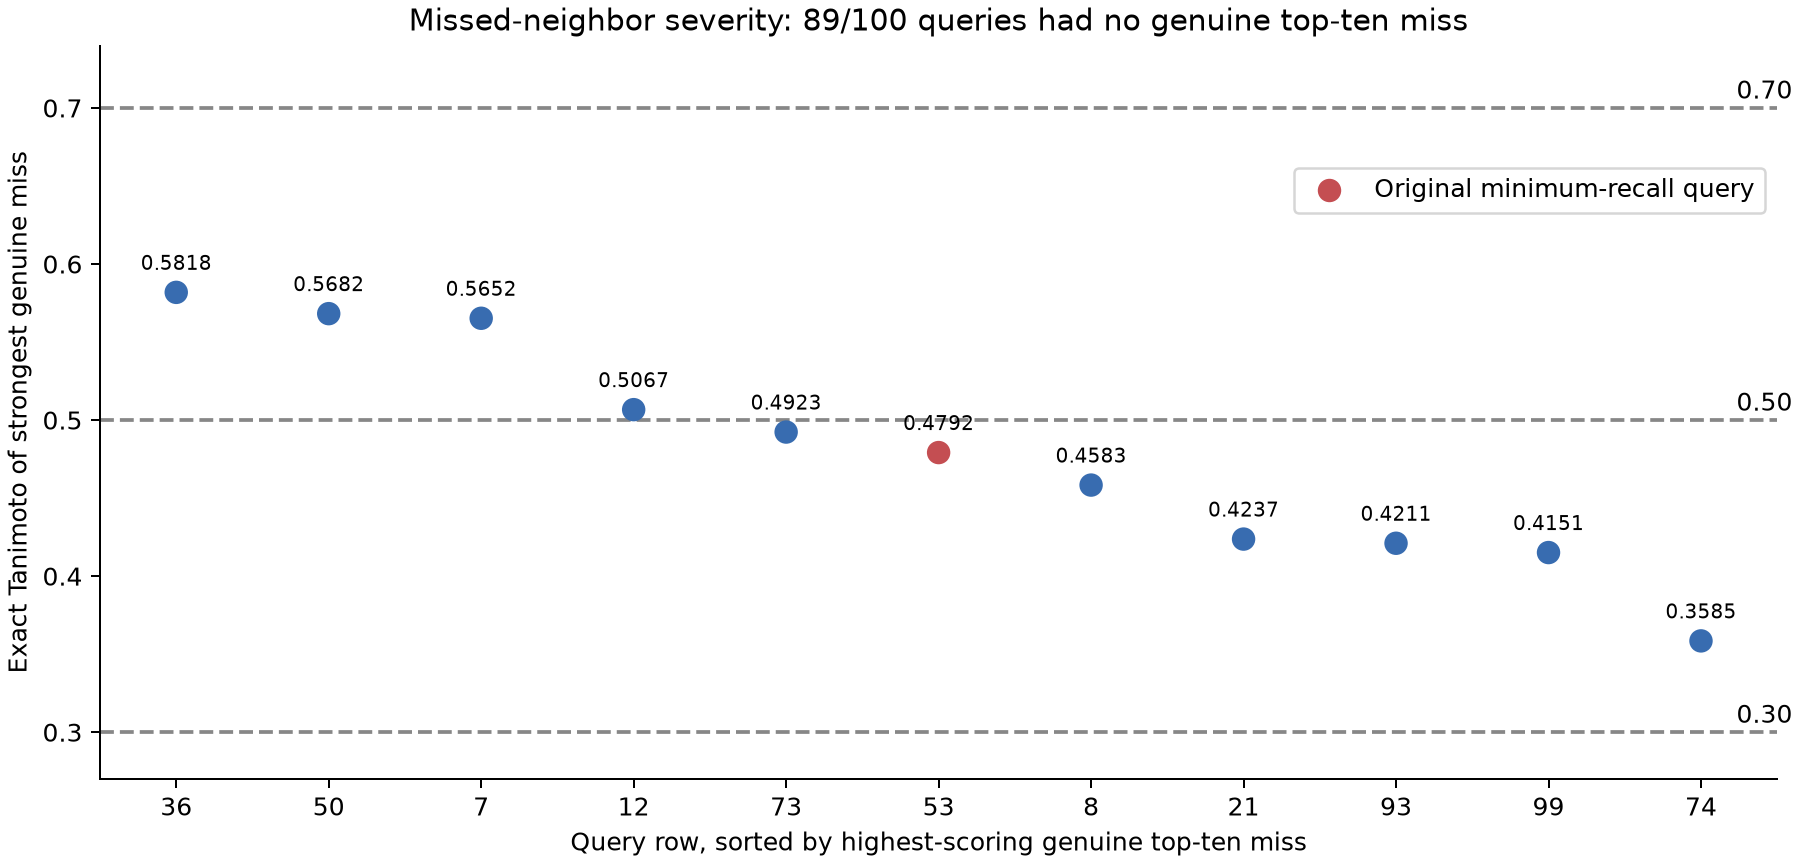

In [6]:
for name in ("worst_query_scores", "display_outcomes", "miss_severity"):
    display(Image(filename=str(REPORT.parent / f"{name}.png")))

## Final deliverable verification

Check that every generated file still matches its manifest and every local report link exists. Original experiment/Notebook 07 preservation and original summary reproduction are asserted during export.

In [7]:
import json
import re
from chemtellect.fingerprint_store import file_info

manifest = json.loads((REPORT.parent / "manifest.json").read_text())
for name, expected in manifest["files"].items():
    assert file_info(REPORT.parent / name) == expected, name
for link in re.findall(r"!?\[[^\]]*\]\(([^)]+)\)", REPORT.read_text()):
    assert (REPORT.parent / link).is_file(), link
assert manifest["status"] == "complete"
assert all(manifest["verification"].values())
print("PASS:", manifest["verification"])
print("Executed notebook and standalone report complete; original experiment preserved.")

PASS: {'all_1600_rows_satisfy_slot_bounds': True, 'all_report_links_resolve': True, 'csv_float64_round_trip': True, 'original_files_unchanged': True, 'original_quality_reproduced': True, 'outcome_partitions_sum_to_100': True, 'primary_display_precision_reproduced': True}
Executed notebook and standalone report complete; original experiment preserved.
